# Q6 (ML). Có thể dự đoán mức lương đăng tuyển từ nội dung tin tuyển dụng không?
**Người phụ trách:** Thành viên 3

**Bài toán:** hồi quy `log(salary_avg_num)` (triệu VND/tháng) trên các tin có lương hợp lệ.
**Feature:** ngành, vùng, mức kinh nghiệm, loại hợp đồng, số tháng kinh nghiệm, số phúc lợi, số kỹ năng,
và văn bản (tên công việc + yêu cầu, TF-IDF 1–2 gram). **Không** dùng bất kỳ cột lương nào (test
`tests/test_modeling.py::test_prepare_xy_no_leakage`).

**Mô hình:** baseline (trung vị) · Ridge (one-hot + TF-IDF) · HistGradientBoosting (TF-IDF → SVD 100 chiều).
**Đánh giá:** chia train/test 80/20 **theo nhóm văn bản** (tin đăng lại có văn bản giống hệt nằm cùng một phía) trước mọi fit; chọn `alpha` của Ridge bằng 5-fold GroupKFold trên train;
MAE/RMSE/R² trên test, đo bằng triệu VND.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.cleaning import load_clean, EXPERIENCE_LEVELS, REGIONS, CATEGORY_LABELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
df["cat"] = df["category"].map(CATEGORY_LABELS)
# Tập có lương hợp lệ: bỏ "Thoả thuận" và ngoại lai
sal = df[~df["salary_negotiable"] & ~df["salary_outlier"]].copy()
print(f"Tất cả tin: {len(df):,} | Tin có lương hợp lệ: {len(sal):,}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

Tất cả tin: 36,457 | Tin có lương hợp lệ: 25,796


In [2]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.inspection import permutation_importance
from src.modeling import prepare_xy, make_models, evaluate, group_train_test_split, RANDOM_STATE, CAT_COLS, NUM_COLS, TEXT_COL

X, y = prepare_xy(df)
X_train, X_test, y_train, y_test = group_train_test_split(X, y, test_size=0.2)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
shared = set(X_train[TEXT_COL].str.lower().str.strip()) & set(X_test[TEXT_COL].str.lower().str.strip())
print("Số văn bản trùng giữa train và test:", len(shared))

Train: 20,643 | Test: 5,153
Số văn bản trùng giữa train và test: 0


## 1. Chọn siêu tham số Ridge (5-fold CV trên train)

In [3]:
models = make_models()
from sklearn.model_selection import GroupKFold
grid = GridSearchCV(models["ridge"], {"regressor__alpha": [0.3, 1, 3, 10]}, cv=GroupKFold(5),
                    scoring="neg_mean_absolute_error", n_jobs=-1)
grid.fit(X_train, y_train, groups=X_train[TEXT_COL].str.lower().str.strip())
cv = pd.DataFrame(grid.cv_results_)[["param_regressor__alpha", "mean_test_score", "std_test_score"]]
cv["MAE (log)"] = -cv.pop("mean_test_score")
display(cv.round(4))
best_alpha = grid.best_params_["regressor__alpha"]
models["ridge"].set_params(regressor__alpha=best_alpha)
print("alpha tốt nhất:", best_alpha)

,param_regressor__alpha,std_test_score,MAE (log)
0,0.3,0.0043,0.2412
1,1.0,0.0039,0.2318
2,3.0,0.0042,0.2330
3,10.0,0.0048,0.2416


alpha tốt nhất: 1


## 2. So sánh mô hình trên tập test

,MAE,RMSE,R2
baseline,5.763,11.567,-0.036
ridge,3.994,9.306,0.329
hgb,4.209,9.619,0.284


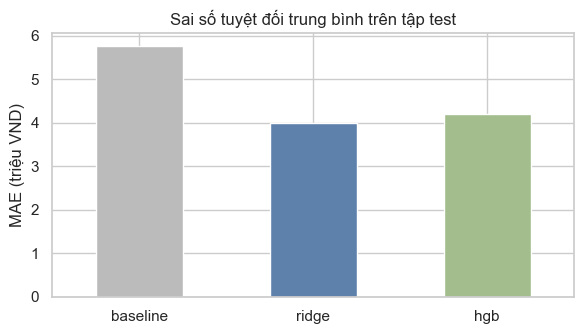

In [4]:
results = evaluate(models, X_train, X_test, y_train, y_test)
display(results.round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
results["MAE"].plot.bar(ax=ax, color=["#bbbbbb", "#5e81ac", "#a3be8c"])
ax.set(ylabel="MAE (triệu VND)", xlabel="", title="Sai số tuyệt đối trung bình trên tập test")
ax.tick_params(axis="x", rotation=0)
savefig("q6_model_comparison.png")

## 3. Giải thích mô hình Ridge — hệ số lớn nhất

*Lưu ý:* một số tin ghi mức lương ngay trong tên/yêu cầu (vd. "Thu nhập upto 20 triệu"). Đó là nội dung thật của tin (ứng viên cũng đọc được), không phải rò rỉ từ cột lương — nhưng giải thích vì sao token như "thu nhập" có hệ số lớn.

In [5]:
mention = X[TEXT_COL].str.contains(r"\d+\s*(triệu|tr\b)", case=False, regex=True)
print(f"Tin có nhắc số tiền trong văn bản: {mention.sum():,} ({mention.mean():.1%})")

Tin có nhắc số tiền trong văn bản: 150 (0.6%)


C:\Users\tlthi\AppData\Local\Temp\ipykernel_2604\637103496.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mention = X[TEXT_COL].str.contains(r"\d+\s*(triệu|tr\b)", case=False, regex=True)


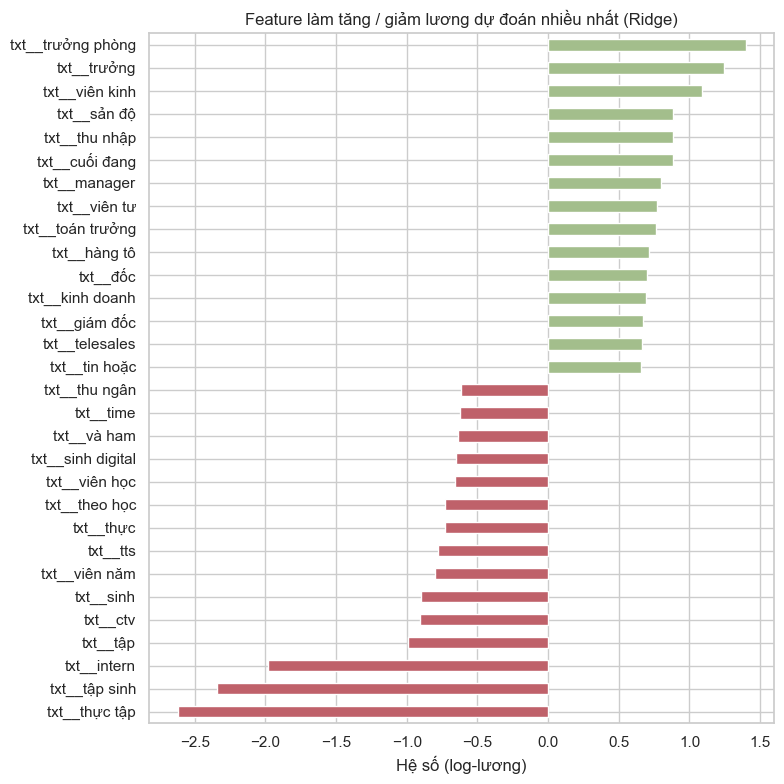

In [6]:
ridge = models["ridge"]
names = ridge.named_steps["pre"].get_feature_names_out()
coef = pd.Series(ridge.named_steps["regressor"].coef_, index=names)
top = pd.concat([coef.nlargest(15), coef.nsmallest(15)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
top.plot.barh(ax=ax, color=np.where(top > 0, "#a3be8c", "#bf616a"))
ax.set(xlabel="Hệ số (log-lương)", ylabel="", title="Feature làm tăng / giảm lương dự đoán nhiều nhất (Ridge)")
savefig("q6_ridge_coefficients.png")

## 4. Giải thích mô hình HGB — permutation importance (theo cột gốc)

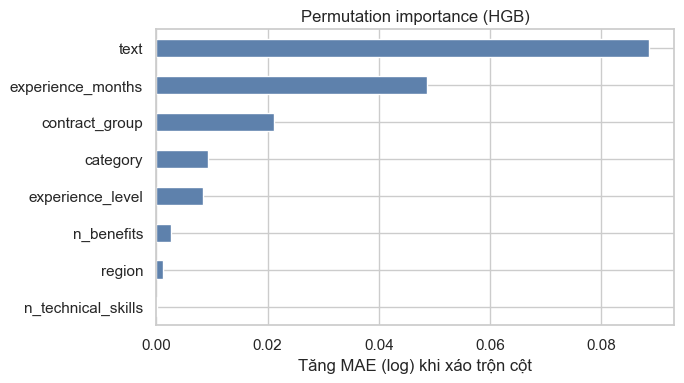

,importance
text,0.0887
experience_months,0.0487
contract_group,0.0211
category,0.0092
experience_level,0.0084
n_benefits,0.0026
region,0.0011
n_technical_skills,0.0001


In [7]:
hgb = models["hgb"]
Xs = X_test.sample(min(3000, len(X_test)), random_state=RANDOM_STATE)
pi = permutation_importance(hgb, Xs, y_test.loc[Xs.index], n_repeats=5, random_state=RANDOM_STATE,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=Xs.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color="#5e81ac")
ax.set(xlabel="Tăng MAE (log) khi xáo trộn cột", ylabel="", title="Permutation importance (HGB)")
savefig("q6_hgb_permutation_importance.png")
imp.sort_values(ascending=False).round(4).to_frame("importance")

## 5. Phân tích sai số

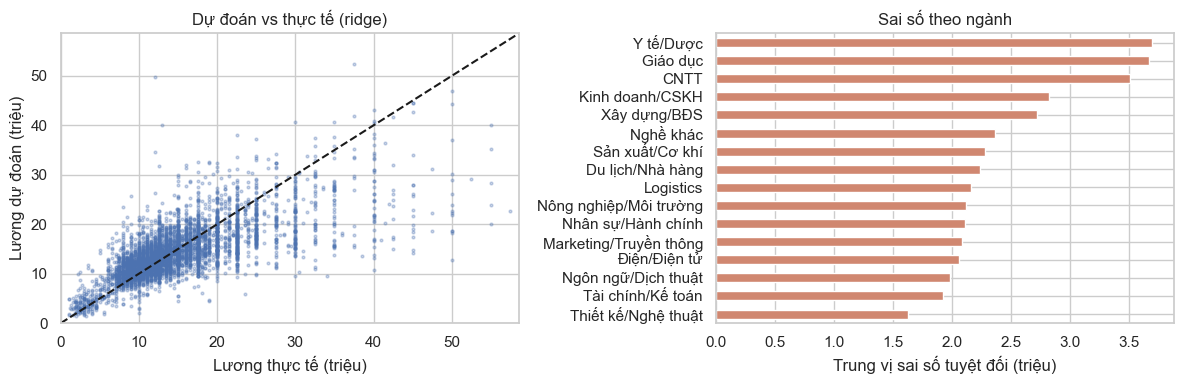

In [8]:
best_name = results["MAE"].idxmin()
best = models[best_name]
pred = np.exp(best.predict(X_test))
true = np.exp(y_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(true, pred, s=4, alpha=0.3)
lim = [0, np.percentile(true, 99)]
axes[0].plot(lim, lim, "k--")
axes[0].set(xlim=lim, ylim=lim, xlabel="Lương thực tế (triệu)", ylabel="Lương dự đoán (triệu)", title=f"Dự đoán vs thực tế ({best_name})")
err = pd.DataFrame({"cat": df.loc[X_test.index, "cat"], "abs_err": np.abs(pred - true)})
mae_cat = err.groupby("cat")["abs_err"].median().sort_values()
mae_cat.plot.barh(ax=axes[1], color="#d08770")
axes[1].set(xlabel="Trung vị sai số tuyệt đối (triệu)", ylabel="", title="Sai số theo ngành")
savefig("q6_error_analysis.png")

## 6. Kết luận

In [9]:
b, m = results.loc["baseline"], results.loc[best_name]
print(f"- Mô hình tốt nhất: {best_name} — MAE {m.MAE:.2f} triệu, R² {m.R2:.2f} "
      f"(baseline MAE {b.MAE:.2f}; giảm {(1 - m.MAE / b.MAE) * 100:.0f}% sai số).")
if m.MAE >= b.MAE:
    print("- CẢNH BÁO: mô hình không vượt baseline — cần xem lại feature.")
print(f"- Feature quan trọng nhất (HGB): {', '.join(imp.sort_values(ascending=False).index[:3])}.")
print(f"- Ngành khó dự đoán nhất: {mae_cat.index[-1]} (sai số trung vị {mae_cat.iloc[-1]:.1f} triệu).")

- Mô hình tốt nhất: ridge — MAE 3.99 triệu, R² 0.33 (baseline MAE 5.76; giảm 31% sai số).
- Feature quan trọng nhất (HGB): text, experience_months, contract_group.
- Ngành khó dự đoán nhất: Y tế/Dược (sai số trung vị 3.7 triệu).


**Hạn chế:** lương là **lương đăng tuyển** (trung bình khoảng min–max); chỉ ~71% tin có lương nên mô hình không áp dụng
cho tin "Thoả thuận" (có thể khác biệt hệ thống, xem Q3); văn bản tiếng Việt chưa tách từ (TF-IDF trên âm tiết + bigram).

*Nhận xét được sinh tự động từ số liệu — thành viên phụ trách cần đọc lại và diễn giải bằng lời của mình.*